# Lane Departure Avoidance & Lane-Change Validation — v4

**Notebook completo: simulacion orientada a objetos + percepcion real (YOLOPv2) +
sensores LiDAR/Radar simulados con la suite real del proyecto + entorno sintetico
de camara.**

Respecto a la v3, esta version agrega:

1. **LiDAR en nube de puntos**, modelando los sensores reales del proyecto: 1x Ouster
   OS1 (360°, mecanico), 1x RoboSense EM4 (frontal, largo alcance), 4x RoboSense E1R
   (punto ciego). Cada punto trae `(x, y, z, intensidad, reflectividad)`.
2. **Radar 4D** (frontal + trasero), incluyendo el parametro de **elevacion** que
   distingue a un radar 4D de uno clasico de 3 dimensiones (rango, azimuth, velocidad).
3. Un **entorno sintetico ligero** que renderiza una "camara" a partir del ground
   truth conocido (posicion exacta de cada vehiculo) — pensado para correr en Colab
   mientras se evalua si vale la pena migrar a un simulador fotorrealista como CARLA
   (que necesita GPU propia, fuera de Colab).

## 0. Instalación de dependencias base

In [ ]:
# pip install opencv-python numpy matplotlib

## 0.1 YOLOPv2 — clonar el repositorio

In [ ]:
# !git clone https://github.com/CAIC-AD/YOLOPv2

## 0.2 YOLOPv2 — descargar pesos y organizarlos

`demo.py` espera el archivo de pesos en `data/weights/yolopv2.pt`. El error de
`torch==1.7.0` al instalar requirements es inofensivo (Colab ya trae PyTorch
reciente).


In [ ]:
# !wget https://github.com/CAIC-AD/YOLOPv2/releases/download/V0.0.1/yolopv2.pt -P YOLOPv2/
!mkdir -p YOLOPv2/data/weights
!mv YOLOPv2/yolopv2.pt YOLOPv2/data/weights/yolopv2.pt
!pip install -r YOLOPv2/requirements.txt

mv: cannot stat 'YOLOPv2/yolopv2.pt': No such file or directory
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'YOLOPv2/requirements.txt'


## 0.3 YOLOPv2 — parchear `demo.py` para correr en CPU

In [ ]:
!sed -i "s/torch\.jit\.load(weights)/torch.jit.load(weights, map_location='cpu')/" YOLOPv2/demo.py
!grep -n "torch.jit.load" YOLOPv2/demo.py

sed: can't read YOLOPv2/demo.py: No such file or directory
grep: YOLOPv2/demo.py: No such file or directory


## 0.4 YOLOPv2 — prueba de inferencia sobre la imagen de ejemplo

In [ ]:
%cd YOLOPv2
!python demo.py --source data/example.jpg --device cpu
%cd ..

/content/YOLOPv2
python3: can't open file '/content/YOLOPv2/demo.py': [Errno 2] No such file or directory
/content


In [ ]:
import glob
import cv2
import matplotlib.pyplot as plt

output_dirs = sorted(glob.glob("YOLOPv2/runs/detect/exp*"))
if output_dirs:
    latest_dir = output_dirs[-1]
    result_imgs = glob.glob(f"{latest_dir}/*.jpg")
    if result_imgs:
        img = cv2.imread(result_imgs[0])
        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Resultado de YOLOPv2: {result_imgs[0]}")
        plt.axis("off")
        plt.show()
    else:
        print("No se encontro imagen de resultado en", latest_dir)
else:
    print("Aun no hay carpeta de salida. Revisa si demo.py corrio sin errores arriba.")

Aun no hay carpeta de salida. Revisa si demo.py corrio sin errores arriba.


## 0.5 Video real de prueba (Udacity `CarND-LaneLines-P1`)

In [ ]:
!git clone https://github.com/udacity/CarND-LaneLines-P1
!ls CarND-LaneLines-P1/test_videos/

TEST_VIDEO_PATH = "CarND-LaneLines-P1/test_videos/solidWhiteRight.mp4"

Cloning into 'CarND-LaneLines-P1'...
remote: Enumerating objects: 265, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 265 (delta 2), reused 1 (delta 1), pack-reused 260 (from 2)
Receiving objects: 100% (265/265), 43.45 MiB | 27.18 MiB/s, done.
Resolving deltas: 100% (123/123), done.
challenge.mp4  solidWhiteRight.mp4  solidYellowLeft.mp4


## 1. Importaciones

In [ ]:
import math
from dataclasses import dataclass, field
from typing import List, Optional, Tuple

import numpy as np
import matplotlib.pyplot as plt

try:
    import cv2
    CV2_AVAILABLE = True
except ImportError:
    CV2_AVAILABLE = False
    print("OpenCV no disponible en este entorno.")

## 2. Parametros del sistema

El vehiculo modelado corresponde a un **Porsche Taycan 4S** real: `length=4.963 m`,
`wheelbase=2.9 m`, `width=1.966 m` coinciden con su ficha tecnica oficial.


In [ ]:
@dataclass
class VehicleParams:
    length: float = 4.963       # m (Porsche Taycan 4S, ficha tecnica oficial)
    wheelbase: float = 2.9      # m
    width: float = 1.966        # m
    mass: float = 2170          # kg (peso en vacio segun DIN)


@dataclass
class ControlParams:
    k_lateral: float = 0.8
    k_heading: float = 1.2
    max_steering_angle: float = np.deg2rad(30)


@dataclass
class SafetyParams:
    min_safe_distance: float = 10.0
    min_safe_ttc: float = 3.0
    lane_safety_margin: float = 0.30


@dataclass
class SimulationParams:
    dt: float = 0.05
    total_time: float = 10.0


@dataclass
class LaneState:
    center: float = 0.0
    heading: float = 0.0
    width: float = 3.5


@dataclass
class VehicleState:
    x: float = 0.0      # posicion longitudinal (m)
    y: float = 0.0      # posicion lateral (m)
    yaw: float = 0.0
    speed: float = 15.0

## 3. Modelo cinematico (Bicycle Model)

In [ ]:
class KinematicBicycleModel:
    def __init__(self, vehicle: VehicleParams):
        self.vehicle = vehicle

    def derivatives(self, state: VehicleState, steering_angle: float) -> Tuple[float, float, float]:
        x_dot = state.speed * np.cos(state.yaw)
        y_dot = state.speed * np.sin(state.yaw)
        yaw_dot = (state.speed / self.vehicle.wheelbase) * np.tan(steering_angle)
        return x_dot, y_dot, yaw_dot

    def step(self, state: VehicleState, steering_angle: float, dt: float) -> VehicleState:
        x_dot, y_dot, yaw_dot = self.derivatives(state, steering_angle)
        return VehicleState(
            x=state.x + x_dot * dt,
            y=state.y + y_dot * dt,
            yaw=state.yaw + yaw_dot * dt,
            speed=state.speed,
        )

## 4. Geometria del carril y errores de control (Lane Keeping)

In [ ]:
class LaneGeometry:
    @staticmethod
    def boundaries(lane: LaneState) -> Tuple[float, float]:
        left = lane.center + lane.width / 2
        right = lane.center - lane.width / 2
        return left, right

    @staticmethod
    def lateral_error(vehicle_y: float, lane: LaneState) -> float:
        return vehicle_y - lane.center

    @staticmethod
    def heading_error(vehicle_yaw: float, lane: LaneState) -> float:
        return vehicle_yaw - lane.heading

    @staticmethod
    def is_departing(vehicle_y: float, lane: LaneState, vehicle: VehicleParams, safety: SafetyParams) -> bool:
        left, right = LaneGeometry.boundaries(lane)
        vehicle_left = vehicle_y + vehicle.width / 2
        vehicle_right = vehicle_y - vehicle.width / 2
        safe_left = left - safety.lane_safety_margin
        safe_right = right + safety.lane_safety_margin
        return vehicle_left > safe_left or vehicle_right < safe_right

## 5. Controlador de Lane Keeping

In [ ]:
class LaneKeepingController:
    def __init__(self, control: ControlParams):
        self.control = control

    def compute_steering(self, lateral_error: float, heading_error: float) -> float:
        steering = -(
            self.control.k_lateral * lateral_error
            + self.control.k_heading * heading_error
        )
        return float(np.clip(steering, -self.control.max_steering_angle, self.control.max_steering_angle))

## 6. Deteccion de carril con OpenCV (pipeline clasico)

=== Prueba con imagen sintetica ===
left_fit: (np.float64(-1.537950315520409), np.float64(708.3607476635515))
right_fit: (np.float64(1.4240673948284568), np.float64(-234.70056626538042))
center_px estimado: 324.55429474558036


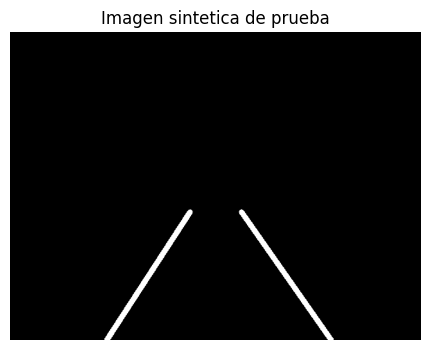

In [ ]:
class ClassicalLaneDetector:
    def __init__(self, canny_low: int = 50, canny_high: int = 150):
        if not CV2_AVAILABLE:
            raise RuntimeError("OpenCV no esta disponible en este entorno.")
        self.canny_low = canny_low
        self.canny_high = canny_high

    def preprocess(self, frame: np.ndarray) -> np.ndarray:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        return cv2.GaussianBlur(gray, (5, 5), 0)

    def edges(self, gray_blurred: np.ndarray) -> np.ndarray:
        return cv2.Canny(gray_blurred, self.canny_low, self.canny_high)

    def region_of_interest(self, edges_img: np.ndarray) -> np.ndarray:
        height, width = edges_img.shape
        polygon = np.array([[
            (int(0.05 * width), height),
            (int(0.45 * width), int(0.6 * height)),
            (int(0.55 * width), int(0.6 * height)),
            (int(0.95 * width), height),
        ]], dtype=np.int32)
        mask = np.zeros_like(edges_img)
        cv2.fillPoly(mask, polygon, 255)
        return cv2.bitwise_and(edges_img, mask)

    def hough_lines(self, roi_edges: np.ndarray) -> Optional[np.ndarray]:
        return cv2.HoughLinesP(
            roi_edges, rho=2, theta=np.pi / 180, threshold=50,
            minLineLength=40, maxLineGap=100,
        )

    def fit_lane_lines(self, lines: Optional[np.ndarray], img_width: int) -> Tuple[Optional[Tuple], Optional[Tuple]]:
        left_fits, right_fits = [], []
        if lines is None:
            return None, None
        for line in lines:
            x1, y1, x2, y2 = line.reshape(-1)
            if x2 == x1:
                continue
            slope = (y2 - y1) / (x2 - x1)
            intercept = y1 - slope * x1
            if slope < -0.3:
                left_fits.append((slope, intercept))
            elif slope > 0.3:
                right_fits.append((slope, intercept))
        left_fit = tuple(np.mean(left_fits, axis=0)) if left_fits else None
        right_fit = tuple(np.mean(right_fits, axis=0)) if right_fits else None
        return left_fit, right_fit

    def estimate_lane_center_px(self, left_fit, right_fit, img_width: int, y_eval: float) -> Optional[float]:
        def x_at_y(fit):
            slope, intercept = fit
            if slope == 0:
                return None
            return (y_eval - intercept) / slope

        if left_fit is not None and right_fit is not None:
            xl, xr = x_at_y(left_fit), x_at_y(right_fit)
            if xl is not None and xr is not None:
                return (xl + xr) / 2
        return None

    def process(self, frame: np.ndarray):
        gray_blurred = self.preprocess(frame)
        edge_img = self.edges(gray_blurred)
        roi_edges = self.region_of_interest(edge_img)
        lines = self.hough_lines(roi_edges)
        left_fit, right_fit = self.fit_lane_lines(lines, frame.shape[1])
        center_px = self.estimate_lane_center_px(left_fit, right_fit, frame.shape[1], frame.shape[0] * 0.95)
        return {"left_fit": left_fit, "right_fit": right_fit, "center_px": center_px, "lines": lines}

if CV2_AVAILABLE:
    synthetic = np.zeros((480, 640, 3), dtype=np.uint8)
    cv2.line(synthetic, (150, 480), (280, 280), (255, 255, 255), 8)
    cv2.line(synthetic, (500, 480), (360, 280), (255, 255, 255), 8)

    detector = ClassicalLaneDetector()
    result = detector.process(synthetic)
    print("=== Prueba con imagen sintetica ===")
    print("left_fit:", result["left_fit"])
    print("right_fit:", result["right_fit"])
    print("center_px estimado:", result["center_px"])

    plt.figure(figsize=(6, 4))
    plt.imshow(cv2.cvtColor(synthetic, cv2.COLOR_BGR2RGB))
    plt.title("Imagen sintetica de prueba")
    plt.axis("off")
    plt.show()

## 6.1 Prueba de `ClassicalLaneDetector` sobre un frame REAL del video

=== Prueba con frame real (Udacity) ===
left_fit: (np.float64(-0.7484659792389154), np.float64(661.4124803083861))
right_fit: (np.float64(0.6302560232660767), np.float64(0.4121221545715506))
center_px estimado: 505.7949586451927


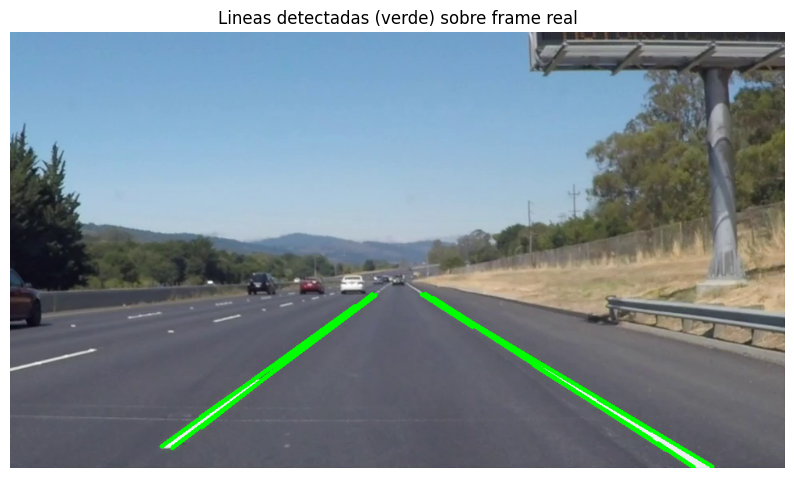

In [ ]:
if CV2_AVAILABLE:
    cap = cv2.VideoCapture(TEST_VIDEO_PATH)
    ret, real_frame = cap.read()
    cap.release()

    if not ret:
        print("No se pudo leer el video. Revisa que la seccion 0.5 se haya corrido bien.")
    else:
        detector = ClassicalLaneDetector()
        result = detector.process(real_frame)
        print("=== Prueba con frame real (Udacity) ===")
        print("left_fit:", result["left_fit"])
        print("right_fit:", result["right_fit"])
        print("center_px estimado:", result["center_px"])

        overlay = real_frame.copy()
        if result["lines"] is not None:
            for line in result["lines"]:
                x1, y1, x2, y2 = line.reshape(-1)
                cv2.line(overlay, (x1, y1), (x2, y2), (0, 255, 0), 3)

        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        plt.title("Lineas detectadas (verde) sobre frame real")
        plt.axis("off")
        plt.show()

## 7. Deteccion de objetos con red preentrenada (YOLO / YOLOPv2)

In [ ]:
@dataclass
class Detection:
    bbox: Tuple[float, float, float, float]
    class_name: str
    confidence: float


class VehicleDetector:
    def __init__(self, weights_path: Optional[str] = None, backend: str = "ultralytics"):
        self.backend = backend
        self.model = None
        if weights_path is not None:
            self._load(weights_path)

    def _load(self, weights_path: str):
        if self.backend == "ultralytics":
            from ultralytics import YOLO
            self.model = YOLO(weights_path)
        elif self.backend == "yolopv2":
            raise NotImplementedError("Integracion directa de YOLOPv2 como libreria pendiente; usar demo.py por ahora.")
        else:
            raise ValueError(f"Backend no soportado: {self.backend}")

    def detect(self, frame: np.ndarray) -> List[Detection]:
        if self.model is None:
            raise RuntimeError("Modelo no cargado. Pasa weights_path al construir VehicleDetector.")
        results = self.model(frame)
        detections = []
        for r in results:
            for box in r.boxes:
                x1, y1, x2, y2 = box.xyxy[0].tolist()
                cls_name = r.names[int(box.cls[0])]
                conf = float(box.conf[0])
                detections.append(Detection((x1, y1, x2, y2), cls_name, conf))
        return detections

## 7.1 YOLOPv2 (`demo.py`) sobre el video real completo

In [ ]:
%cd YOLOPv2
!python demo.py --source ../CarND-LaneLines-P1/test_videos/solidWhiteRight.mp4 --device cpu
%cd ..

/content/YOLOPv2
python3: can't open file '/content/YOLOPv2/demo.py': [Errno 2] No such file or directory
/content


In [ ]:
import glob
output_videos = sorted(glob.glob("YOLOPv2/runs/detect/exp*/*.mp4"))
if output_videos:
    print("Video de resultado generado en:", output_videos[-1])
else:
    print("Aun no hay video de salida. Revisa si el comando de arriba corrio sin errores.")

Aun no hay video de salida. Revisa si el comando de arriba corrio sin errores.


## 7.2 Ver el video resultante dentro del notebook

`demo.py` guarda el video con el codec `mp4v`, que la mayoria de navegadores no
reproducen directamente. Esta celda lo reconvierte a H.264 con `ffmpeg` y lo
incrusta para verlo con controles de play/pause, directo en la salida de la celda.


In [ ]:
import glob
import subprocess
from base64 import b64encode
from IPython.display import HTML

output_videos = sorted(glob.glob("YOLOPv2/runs/detect/exp*/*.mp4"))

if not output_videos:
    print("No se encontro ningun video de salida. Revisa que la seccion 7.1 haya terminado sin errores.")
else:
    original_path = output_videos[-1]
    print("Video encontrado en:", original_path)

    reencoded_path = original_path.replace(".mp4", "_web.mp4")
    subprocess.run(
        ["ffmpeg", "-y", "-i", original_path, "-vcodec", "libx264", "-pix_fmt", "yuv420p", reencoded_path],
        check=True,
    )

    video_bytes = open(reencoded_path, "rb").read()
    data_url = "data:video/mp4;base64," + b64encode(video_bytes).decode()

    display(HTML(f'<video width="640" controls><source src="{data_url}" type="video/mp4"></video>'))

No se encontro ningun video de salida. Revisa que la seccion 7.1 haya terminado sin errores.


## 7.3 LDA-32: Obtener distancia y posición de objetos por cámara

`VehicleDetector` ya da cajas delimitadoras (bounding boxes) de cada vehículo
detectado, pero en píxeles — no en metros. Esta sección agrega la pieza que
faltaba: convertir esa caja a una distancia y posición lateral reales, asumiendo
piso plano y que la base del bounding box toca el suelo.

In [ ]:
@dataclass
class CameraCalibration:
    """Calibracion de la camara real. TODO: reemplazar por los valores reales
    de la AUMOVIO FSC 332 una vez calibrada."""
    focal_length_px: float = 700.0
    camera_height: float = 1.4     # m, altura de montaje sobre el piso
    image_width: int = 960
    image_height: int = 540


class CameraObjectLocalizer:
    """LDA-32: estima distancia y posicion lateral de un objeto detectado por
    camara, asumiendo piso plano y que la base del bounding box toca el suelo."""

    def __init__(self, calibration: CameraCalibration):
        self.calib = calibration

    def estimate_position(self, detection: Detection) -> Optional[Tuple[float, float]]:
        x1, y1, x2, y2 = detection.bbox
        u = (x1 + x2) / 2
        v = y2
        cx = self.calib.image_width / 2
        cy = self.calib.image_height / 2
        if v <= cy:
            return None
        forward_distance = self.calib.focal_length_px * self.calib.camera_height / (v - cy)
        lateral_offset = (u - cx) * forward_distance / self.calib.focal_length_px
        return forward_distance, lateral_offset

    def to_tracked_object(self, detection, vehicle, object_id, speed_estimate=0.0, lane=0):
        position = self.estimate_position(detection)
        if position is None:
            return None
        forward_distance, lateral_offset = position
        return TrackedObject(
            object_id=object_id,
            x=vehicle.x + forward_distance,
            y=vehicle.y + lateral_offset,
            speed=speed_estimate,
            lane=lane,
        )


# Prueba round-trip: proyectamos una posicion CONOCIDA a pixeles y confirmamos
# que la recuperamos sin error
def _world_to_pixel_test(forward_distance, lateral_offset, calib):
    cx, cy = calib.image_width / 2, calib.image_height / 2
    u = cx + calib.focal_length_px * (lateral_offset / forward_distance)
    v = cy + calib.focal_length_px * (calib.camera_height / forward_distance)
    return u, v

calibration = CameraCalibration()
localizer = CameraObjectLocalizer(calibration)

print("=== LDA-32: prueba round-trip ===")
test_cases = [(25.0, 1.8), (55.0, -0.2), (10.0, 0.0), (80.0, 3.0)]
for d_real, lat_real in test_cases:
    u, v = _world_to_pixel_test(d_real, lat_real, calibration)
    det = Detection(bbox=(u-20, v-60, u+20, v), class_name="car", confidence=0.9)
    d_est, lat_est = localizer.estimate_position(det)
    status = "PASS" if abs(d_real-d_est) < 1e-6 and abs(lat_real-lat_est) < 1e-6 else "FAIL"
    print(f"[{status}] distancia real={d_real:.1f}m estimada={d_est:.3f}m | lateral real={lat_real:.1f}m estimado={lat_est:.3f}m")

=== LDA-32: prueba round-trip ===
[PASS] distancia real=25.0m estimada=25.000m | lateral real=1.8m estimado=1.800m
[PASS] distancia real=55.0m estimada=55.000m | lateral real=-0.2m estimado=-0.200m
[PASS] distancia real=10.0m estimada=10.000m | lateral real=0.0m estimado=0.000m
[PASS] distancia real=80.0m estimada=80.000m | lateral real=3.0m estimado=3.000m


## 8. Validacion de cambio de carril: tipos de datos de objetos

`TrackedObject` se define aqui (antes de tracking/fusion/sensores) porque varias
secciones siguientes ya lo necesitan.


In [ ]:
@dataclass
class TrackedObject:
    object_id: int
    x: float
    y: float
    speed: float
    lane: int
    data_is_valid: bool = True

## 9. Tracking (Kalman filter propio / gancho para ByteTrack)

In [ ]:
class SimpleKalmanTracker:
    def __init__(self, dt: float = 0.05):
        self.dt = dt
        self.x = np.zeros((4, 1))
        self.P = np.eye(4) * 10.0
        self.F = np.array([
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1],
        ])
        self.H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0],
        ])
        self.Q = np.eye(4) * 0.01
        self.R = np.eye(2) * 1.0

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x

    def update(self, measurement_xy: Tuple[float, float]):
        z = np.array(measurement_xy).reshape(2, 1)
        y = z - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ y
        self.P = (np.eye(4) - K @ self.H) @ self.P
        return self.x

    @property
    def velocity(self) -> Tuple[float, float]:
        return float(self.x[2, 0]), float(self.x[3, 0])

## 10. Sensor Fusion (Kalman / EKF) — punto de extension

In [ ]:
@dataclass
class FusedObject:
    x: float
    y: float
    speed: float
    confidence: float
    sources: List[str] = field(default_factory=list)

class SensorFusionEKF:
    def fuse(self, camera_obj: Optional[dict], radar_obj: Optional[dict], lidar_obj: Optional[dict]) -> Optional[FusedObject]:
        candidates = [o for o in (camera_obj, radar_obj, lidar_obj) if o is not None]
        if not candidates:
            return None

        sources = []
        xs, ys, speeds, weights = [], [], [], []
        for obj, name in zip((camera_obj, radar_obj, lidar_obj), ("camera", "radar", "lidar")):
            if obj is None:
                continue
            sources.append(name)
            xs.append(obj.get("x", 0.0))
            ys.append(obj.get("y", 0.0))
            speeds.append(obj.get("speed", 0.0))
            weights.append(obj.get("confidence", 0.5))

        weights = np.array(weights)
        weights = weights / weights.sum()
        return FusedObject(
            x=float(np.dot(xs, weights)),
            y=float(np.dot(ys, weights)),
            speed=float(np.dot(speeds, weights)),
            confidence=float(weights.max()),
            sources=sources,
        )

## 11. LiDAR — nube de puntos con la suite real del proyecto

Sensores modelados (seccion 7.3 del documento):
- **1x Ouster OS1** — mecanico, 360°, techo del vehiculo.
- **1x RoboSense EM4** — solido, frontal, largo alcance.
- **4x RoboSense E1R** — solido, punto ciego (frontal-izq, frontal-der, trasero-izq, trasero-der).

Cada punto trae `(x, y, z, intensity, reflectivity)` — **intensidad** es que tan
fuerte volvio el pulso laser (depende de distancia/angulo); **reflectividad** es
una propiedad calibrada del material, casi independiente de la distancia (sirve
para distinguir, por ejemplo, un letrero reflectante de pintura de carril normal).


In [ ]:
@dataclass
class LidarUnitSpec:
    name: str
    mount_position: Tuple[float, float, float]  # x, y, z relativo al centro del vehiculo (m)
    fov_deg: float
    max_range: float
    scan_type: str  # "mechanical_360" | "solid_state_long_range" | "solid_state_blind_spot"
    points_per_object: int = 20

LIDAR_SUITE = [
    LidarUnitSpec("ouster_os1_roof", (0.0, 0.0, 1.6), fov_deg=360.0, max_range=120.0,
                  scan_type="mechanical_360", points_per_object=30),
    LidarUnitSpec("robosense_em4_front", (2.4, 0.0, 0.5), fov_deg=30.0, max_range=200.0,
                  scan_type="solid_state_long_range", points_per_object=15),
    LidarUnitSpec("robosense_e1r_front_left", (2.3, 0.9, 0.4), fov_deg=120.0, max_range=30.0,
                  scan_type="solid_state_blind_spot", points_per_object=10),
    LidarUnitSpec("robosense_e1r_front_right", (2.3, -0.9, 0.4), fov_deg=120.0, max_range=30.0,
                  scan_type="solid_state_blind_spot", points_per_object=10),
    LidarUnitSpec("robosense_e1r_rear_left", (-2.3, 0.9, 0.4), fov_deg=120.0, max_range=30.0,
                  scan_type="solid_state_blind_spot", points_per_object=10),
    LidarUnitSpec("robosense_e1r_rear_right", (-2.3, -0.9, 0.4), fov_deg=120.0, max_range=30.0,
                  scan_type="solid_state_blind_spot", points_per_object=10),
]

@dataclass
class LidarPoint:
    x: float
    y: float
    z: float
    intensity: float      # 0-255: fuerza del retorno (depende de distancia/angulo)
    reflectivity: float   # 0-100%: propiedad del material, casi independiente de la distancia


class LidarPointCloudSimulator:
    """Simula una NUBE DE PUNTOS por sensor (no un solo x,y por objeto), como
    daria el hardware real. No hay LiDAR fisico conectado todavia; esto permite
    probar el resto del pipeline (ground plane segmentation, fusion) mientras tanto."""

    def __init__(self, rng: Optional[np.random.Generator] = None):
        self.rng = rng or np.random.default_rng()

    def _distance_and_angle(self, vehicle: VehicleState, unit: LidarUnitSpec, obj: TrackedObject):
        sensor_x = vehicle.x + unit.mount_position[0] * np.cos(vehicle.yaw) - unit.mount_position[1] * np.sin(vehicle.yaw)
        sensor_y = vehicle.y + unit.mount_position[0] * np.sin(vehicle.yaw) + unit.mount_position[1] * np.cos(vehicle.yaw)
        dx, dy = obj.x - sensor_x, obj.y - sensor_y
        distance = np.hypot(dx, dy)
        angle = np.degrees(np.arctan2(dy, dx) - vehicle.yaw)
        angle = (angle + 180) % 360 - 180
        return distance, angle

    def scan_unit(self, vehicle: VehicleState, unit: LidarUnitSpec,
                  objects: List[TrackedObject], vehicle_params: VehicleParams) -> dict:
        result = {}
        for obj in objects:
            distance, angle = self._distance_and_angle(vehicle, unit, obj)
            if distance > unit.max_range or abs(angle) > unit.fov_deg / 2:
                continue

            points = []
            noise_std = 0.02 if "solid_state" in unit.scan_type else 0.04
            for _ in range(unit.points_per_object):
                px = obj.x + self.rng.uniform(-vehicle_params.length / 2, vehicle_params.length / 2) + self.rng.normal(0, noise_std)
                py = obj.y + self.rng.uniform(-vehicle_params.width / 2, vehicle_params.width / 2) + self.rng.normal(0, noise_std)
                pz = self.rng.uniform(0.0, 1.6)
                intensity = float(np.clip(self.rng.normal(120, 30), 0, 255))
                reflectivity = float(np.clip(self.rng.normal(40, 15), 0, 100))
                points.append(LidarPoint(px, py, pz, intensity, reflectivity))

            result[obj.object_id] = points
        return result

    def scan_all(self, vehicle: VehicleState, objects: List[TrackedObject], vehicle_params: VehicleParams) -> dict:
        combined = {obj.object_id: [] for obj in objects}
        for unit in LIDAR_SUITE:
            unit_result = self.scan_unit(vehicle, unit, objects, vehicle_params)
            for obj_id, points in unit_result.items():
                combined[obj_id].extend(points)
        return combined

# Prueba rapida
_ego = VehicleState(x=0.0, y=0.0, yaw=0.0, speed=15.0)
_objects_demo = [
    TrackedObject(object_id=1, x=40.0, y=3.5, speed=13.0, lane=1),
    TrackedObject(object_id=2, x=15.0, y=-1.0, speed=15.0, lane=0),  # dentro del rango de punto ciego
]
_lidar = LidarPointCloudSimulator()
_cloud = _lidar.scan_all(_ego, _objects_demo, VehicleParams())
for obj_id, points in _cloud.items():
    print(f"Objeto {obj_id}: {len(points)} puntos de LiDAR detectados")

Objeto 1: 45 puntos de LiDAR detectados
Objeto 2: 85 puntos de LiDAR detectados


## 11.1 Ground Plane Segmentation (RANSAC) — para cuando haya nube de puntos real

Tecnica estandar para separar "esto es piso/carretera" de "esto es un obstaculo"
en una nube de puntos real: se ajusta un plano `ax + by + cz + d = 0` (con `z≈0`
para una carretera razonablemente plana) usando RANSAC, y los puntos a distancia
`d <= epsilon_ground` del plano se consideran piso; el resto, obstaculos.

Esto **no se usa todavia** con la nube de puntos simulada de arriba (ya viene
"limpia", sin puntos de piso) — queda implementado para cuando conectes LiDAR real
o uses un dataset como nuScenes/Waymo Open Dataset, que si traen puntos de piso
mezclados con los de obstaculos.


In [ ]:
def fit_ground_plane_ransac(points_xyz: np.ndarray, epsilon_ground: float = 0.15,
                              n_iterations: int = 100, rng: Optional[np.random.Generator] = None):
    """RANSAC planar fitting: ax + by + cz + d = 0.
    points_xyz: array (N, 3). Devuelve (plane_coeffs, ground_mask).
    LIMITACION (igual que en la diapositiva de referencia): esto asume terreno
    razonablemente plano; en terreno con pendiente o curvatura pronunciada, falla."""
    rng = rng or np.random.default_rng()
    n_points = points_xyz.shape[0]
    if n_points < 3:
        return None, np.zeros(n_points, dtype=bool)

    best_inliers = 0
    best_plane = None
    best_mask = np.zeros(n_points, dtype=bool)

    for _ in range(n_iterations):
        sample_idx = rng.choice(n_points, size=3, replace=False)
        p1, p2, p3 = points_xyz[sample_idx]
        v1, v2 = p2 - p1, p3 - p1
        normal = np.cross(v1, v2)
        norm = np.linalg.norm(normal)
        if norm < 1e-6:
            continue
        a, b, c = normal / norm
        d = -np.dot((a, b, c), p1)

        distances = np.abs(points_xyz @ np.array([a, b, c]) + d)
        mask = distances <= epsilon_ground
        inliers = int(mask.sum())

        if inliers > best_inliers:
            best_inliers = inliers
            best_plane = (a, b, c, d)
            best_mask = mask

    return best_plane, best_mask

## 12. Radar 4D — con elevacion

2x radares 4D (frontal + trasero). La diferencia frente a un radar clasico de 3
dimensiones (rango, azimuth, velocidad) es el cuarto parametro: **elevacion** —
util para distinguir un objeto a nivel de piso de uno elevado (un puente, un
letrero).


In [ ]:
@dataclass
class RadarUnitSpec:
    name: str
    mount_position: Tuple[float, float, float]
    facing_deg: float
    fov_deg: float = 120.0
    max_range: float = 250.0

RADAR_SUITE = [
    RadarUnitSpec("radar_4d_front", (2.4, 0.0, 0.5), facing_deg=0.0),
    RadarUnitSpec("radar_4d_rear", (-2.4, 0.0, 0.5), facing_deg=180.0),
]

@dataclass
class RadarDetection:
    range_m: float
    azimuth_deg: float
    elevation_deg: float
    relative_velocity: float


class Radar4DSimulator:
    def __init__(self, rng: Optional[np.random.Generator] = None):
        self.rng = rng or np.random.default_rng()

    def scan_unit(self, vehicle: VehicleState, unit: RadarUnitSpec, objects: List[TrackedObject]) -> dict:
        result = {}
        for obj in objects:
            dx, dy = obj.x - vehicle.x, obj.y - vehicle.y
            distance = np.hypot(dx, dy)
            angle = np.degrees(np.arctan2(dy, dx) - vehicle.yaw) - unit.facing_deg
            angle = (angle + 180) % 360 - 180
            if distance > unit.max_range or abs(angle) > unit.fov_deg / 2:
                continue

            result[obj.object_id] = RadarDetection(
                range_m=float(distance + self.rng.normal(0, 0.1)),
                azimuth_deg=float(angle + self.rng.normal(0, 0.3)),
                elevation_deg=float(self.rng.normal(0.0, 0.5)),
                relative_velocity=float((vehicle.speed - obj.speed) + self.rng.normal(0, 0.1)),
            )
        return result

    def scan_all(self, vehicle: VehicleState, objects: List[TrackedObject]) -> dict:
        combined = {}
        for unit in RADAR_SUITE:
            for obj_id, det in self.scan_unit(vehicle, unit, objects).items():
                combined.setdefault(obj_id, []).append(det)
        return combined


_radar = Radar4DSimulator()
_radar_detections = _radar.scan_all(_ego, _objects_demo)
for obj_id, dets in _radar_detections.items():
    for d in dets:
        print(f"Objeto {obj_id}: rango={d.range_m:.1f}m azimuth={d.azimuth_deg:.1f}° "
              f"elevacion={d.elevation_deg:.1f}° vel_relativa={d.relative_velocity:.1f}m/s")

Objeto 1: rango=40.4m azimuth=5.0° elevacion=0.2° vel_relativa=2.0m/s
Objeto 2: rango=15.1m azimuth=-3.9° elevacion=0.4° vel_relativa=0.1m/s


## 13. Entorno sintetico: renderizar una "camara" desde el ground truth conocido

Este es el punto central de la propuesta de valor: **ya sabemos la posicion exacta
de cada carro** (son `TrackedObject` con x, y conocidos, no detectados). Esta clase
proyecta esa escena conocida a una imagen tipo "vista de camara", usando un modelo
de perspectiva simple (pinhole). No es fotorrealista — es el camino ligero que
corre en Colab hoy; el camino fotorrealista (CARLA) requiere GPU propia y queda
para cuando tengas esa computadora prestada.


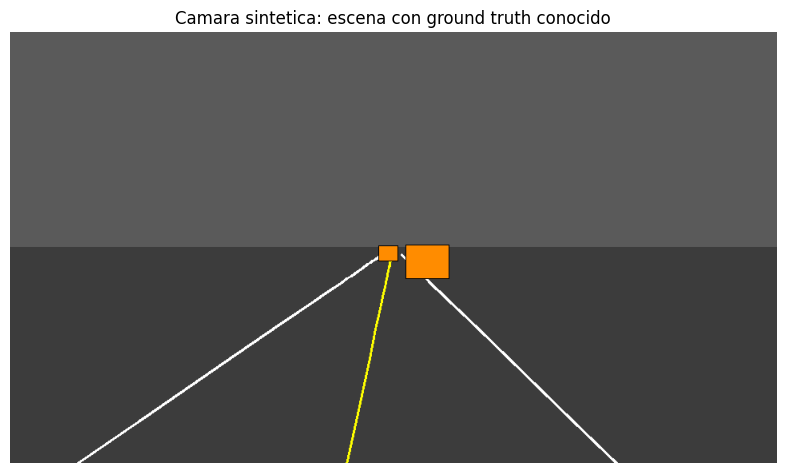

center_px detectado por ClassicalLaneDetector: 531.9475312350494
Centro real de la imagen (referencia): 480.0


In [ ]:
@dataclass
class PinholeCameraParams:
    image_width: int = 960
    image_height: int = 540
    focal_length_px: float = 700.0
    camera_height: float = 1.4   # m, similar a una camara montada tras el parabrisas

class SyntheticCameraRenderer:
    """Renderiza una escena 2D (carril + vehiculos con posicion CONOCIDA) como si
    fuera vista por una camara frontal. Util para probar ClassicalLaneDetector o
    YOLOPv2 con datos donde el ground truth es exacto (lo pusimos nosotros),
    en vez de depender de video real o de montar CARLA."""

    def __init__(self, camera: PinholeCameraParams):
        self.camera = camera

    def _world_to_pixel(self, forward_distance: float, lateral_offset: float) -> Optional[Tuple[int, int]]:
        if forward_distance <= 1.0:
            return None  # detras de la camara o demasiado cerca
        cx = self.camera.image_width / 2
        cy = self.camera.image_height / 2
        u = cx + self.camera.focal_length_px * (lateral_offset / forward_distance)
        v = cy + self.camera.focal_length_px * (self.camera.camera_height / forward_distance)
        return int(u), int(v)

    def render(self, vehicle: VehicleState, lane: LaneState,
               objects: List[TrackedObject], vehicle_params: VehicleParams) -> np.ndarray:
        img = np.full((self.camera.image_height, self.camera.image_width, 3), (90, 90, 90), dtype=np.uint8)
        cv2.rectangle(img, (0, self.camera.image_height // 2), (self.camera.image_width, self.camera.image_height),
                      (60, 60, 60), -1)  # piso

        # Carriles (centro, izquierdo, derecho) como lineas que convergen al horizonte
        for offset, color in [(0.0, (0, 255, 255)),
                               (lane.width / 2, (255, 255, 255)),
                               (-lane.width / 2, (255, 255, 255))]:
            pts = []
            for d in np.linspace(2, 100, 40):
                p = self._world_to_pixel(d, lane.center + offset - vehicle.y)
                if p is not None:
                    pts.append(p)
            if len(pts) >= 2:
                cv2.polylines(img, [np.array(pts, dtype=np.int32)], False, color, 2)

        # Vehiculos (tamaño en pixeles decrece con la distancia, efecto de perspectiva)
        for obj in objects:
            forward_distance = obj.x - vehicle.x
            lateral_offset = obj.y - vehicle.y
            center = self._world_to_pixel(forward_distance, lateral_offset)
            if center is None:
                continue
            width_px = max(4, int(self.camera.focal_length_px * vehicle_params.width / forward_distance))
            height_px = max(3, int(self.camera.focal_length_px * 1.5 / forward_distance))
            u, v = center
            top_left = (u - width_px // 2, v - height_px)
            bottom_right = (u + width_px // 2, v)
            cv2.rectangle(img, top_left, bottom_right, (0, 140, 255), -1)
            cv2.rectangle(img, top_left, bottom_right, (0, 0, 0), 1)

        return img

if CV2_AVAILABLE:
    camera_params = PinholeCameraParams()
    renderer = SyntheticCameraRenderer(camera_params)

    demo_lane = LaneState(center=0.0, heading=0.0, width=3.5)
    demo_ego = VehicleState(x=0.0, y=0.3, yaw=0.0, speed=15.0)  # ligeramente desviado, a proposito
    demo_objects = [
        TrackedObject(object_id=1, x=25.0, y=1.8, speed=13.0, lane=1),
        TrackedObject(object_id=2, x=55.0, y=-0.2, speed=15.0, lane=0),
    ]

    synthetic_frame = renderer.render(demo_ego, demo_lane, demo_objects, VehicleParams())

    plt.figure(figsize=(10, 5.6))
    plt.imshow(cv2.cvtColor(synthetic_frame, cv2.COLOR_BGR2RGB))
    plt.title("Camara sintetica: escena con ground truth conocido")
    plt.axis("off")
    plt.show()

    # Esto es lo interesante: le damos esta imagen sintetica a nuestro PROPIO detector
    # y comparamos lo que detecta contra lo que YA SABEMOS que es verdad.
    detector = ClassicalLaneDetector()
    synth_result = detector.process(synthetic_frame)
    print("center_px detectado por ClassicalLaneDetector:", synth_result["center_px"])
    print("Centro real de la imagen (referencia):", camera_params.image_width / 2)

## 14. Validacion de cambio de carril (Lane-Change Validation)

In [ ]:
class LaneChangeValidator:
    def __init__(self, safety: SafetyParams):
        self.safety = safety

    def target_lane(self, current_lane: int, direction: str) -> Optional[int]:
        if direction == "LEFT":
            return current_lane + 1
        if direction == "RIGHT":
            return current_lane - 1
        return None

    def objects_in_lane(self, lane: int, objects: List[TrackedObject]) -> List[TrackedObject]:
        return [obj for obj in objects if obj.lane == lane]

    def distance(self, vx: float, vy: float, ox: float, oy: float) -> float:
        return float(np.sqrt((ox - vx) ** 2 + (oy - vy) ** 2))

    def relative_speed(self, vehicle_speed: float, object_speed: float) -> float:
        return vehicle_speed - object_speed

    def ttc(self, distance: float, relative_speed: float) -> float:
        if relative_speed <= 0:
            return np.inf
        return distance / relative_speed

    def is_safe_distance(self, distance: float) -> bool:
        return distance >= self.safety.min_safe_distance

    def is_safe_ttc(self, ttc: float) -> bool:
        return True if np.isinf(ttc) else ttc >= self.safety.min_safe_ttc

    def can_change_lane(self, direction: str, vehicle: VehicleState, current_lane: int, objects: List[TrackedObject]) -> bool:
        target = self.target_lane(current_lane, direction)
        if target is None:
            return False

        target_objects = self.objects_in_lane(target, objects)
        if len(target_objects) == 0:
            return True

        for obj in target_objects:
            if not obj.data_is_valid:
                return False

            distance = self.distance(vehicle.x, vehicle.y, obj.x, obj.y)
            rel_speed = self.relative_speed(vehicle.speed, obj.speed)
            ttc = self.ttc(distance, rel_speed)

            if not self.is_safe_distance(distance):
                return False
            if not self.is_safe_ttc(ttc):
                return False

        return True

## 15. Simulador integrado

In [ ]:
class Simulator:
    def __init__(self, vehicle: VehicleParams, control: ControlParams,
                 safety: SafetyParams, sim: SimulationParams, lane: LaneState):
        self.vehicle_params = vehicle
        self.sim_params = sim
        self.lane = lane
        self.bicycle_model = KinematicBicycleModel(vehicle)
        self.controller = LaneKeepingController(control)
        self.validator = LaneChangeValidator(safety)

        self.state = VehicleState(speed=15.0)
        self.history = {k: [] for k in
                         ["time", "x", "y", "yaw", "lateral_error", "heading_error", "steering", "departure"]}

    def run(self):
        t = 0.0
        while t <= self.sim_params.total_time:
            lateral_error = LaneGeometry.lateral_error(self.state.y, self.lane)
            heading_error = LaneGeometry.heading_error(self.state.yaw, self.lane)
            steering = self.controller.compute_steering(lateral_error, heading_error)
            departure = LaneGeometry.is_departing(self.state.y, self.lane, self.vehicle_params,
                                                   self.validator.safety)

            self.history["time"].append(t)
            self.history["x"].append(self.state.x)
            self.history["y"].append(self.state.y)
            self.history["yaw"].append(self.state.yaw)
            self.history["lateral_error"].append(lateral_error)
            self.history["heading_error"].append(heading_error)
            self.history["steering"].append(steering)
            self.history["departure"].append(departure)

            self.state = self.bicycle_model.step(self.state, steering, self.sim_params.dt)
            t += self.sim_params.dt

    def evaluate_lane_change(self, current_lane: int, objects: List[TrackedObject]):
        can_left = self.validator.can_change_lane("LEFT", self.state, current_lane, objects)
        can_right = self.validator.can_change_lane("RIGHT", self.state, current_lane, objects)
        return can_left, can_right

## 16. Ejecutar la simulacion

In [ ]:
vehicle_params = VehicleParams()
control_params = ControlParams()
safety_params = SafetyParams()
sim_params = SimulationParams()
lane_state = LaneState()

simulator = Simulator(vehicle_params, control_params, safety_params, sim_params, lane_state)
simulator.run()

objects = [
    TrackedObject(object_id=1, x=40.0, y=3.5, speed=13.0, lane=1),
    TrackedObject(object_id=2, x=70.0, y=-3.5, speed=15.0, lane=-1),
]

can_left, can_right = simulator.evaluate_lane_change(current_lane=0, objects=objects)

print("==========================================")
print("LANE CHANGE VALIDATION")
print("==========================================")
print("Can change LEFT:", can_left)
print("Can change RIGHT:", can_right)
print()
print("==========================================")
print("SIMULATION RESULTS")
print("==========================================")
print("Final X:", round(simulator.state.x, 3), "m")
print("Final Y:", round(simulator.state.y, 3), "m")
print("Final Yaw:", round(np.rad2deg(simulator.state.yaw), 3), "degrees")
print("Final lateral error:", round(simulator.history["lateral_error"][-1], 3), "m")
print("Final steering:", round(np.rad2deg(simulator.history["steering"][-1]), 3), "degrees")
print()
print("==========================================")
print("LANE DEPARTURE")
print("==========================================")
print("Departure detected:", any(simulator.history["departure"]))
print("Number of detected steps:", sum(simulator.history["departure"]))

LANE CHANGE VALIDATION
Can change LEFT: True
Can change RIGHT: True

SIMULATION RESULTS
Final X: 150.0 m
Final Y: 0.0 m
Final Yaw: 0.0 degrees
Final lateral error: 0.0 m
Final steering: -0.0 degrees

LANE DEPARTURE
Departure detected: False
Number of detected steps: 0


## 16.1 Animación: alerta de salida de carril + corrección automática + validación de cambio de carril
1. El ego arranca **centrado** y maneja derecho.
2. Una pequeña perturbación simulada (`DISTURBANCE_STEERING`, como una falla o
   distracción) lo hace **derivar lentamente** hacia un lado — el controlador de
   Lane Keeping todavía NO esta interviniendo en esta fase.
3. En cuanto `LaneGeometry.is_departing()` detecta que se sale del margen de
   seguridad del carril, se dispara una **alerta visual** ("¡ALERTA: SALIENDO DEL
   CARRIL!") y, desde ese momento, `LaneKeepingController` se activa y **corrige
   el rumbo** hasta volver al centro.
4. Una vez centrado, se queda estable (ya no oscila) por el resto del video.
5. En paralelo, sigue corriendo `LaneChangeValidator` contra el otro vehículo en
   el carril izquierdo, igual que antes.


In [ ]:
def render_topdown(vehicle, lane, objects, vehicle_params, can_change_left,
                    canvas_width=960, canvas_height=260):
    """Vista de dron (bird's-eye) de la misma escena que ve SyntheticCameraRenderer."""
    canvas = np.full((canvas_height, canvas_width, 3), (50, 110, 50), dtype=np.uint8)
    x_min, x_max = vehicle.x - 15, vehicle.x + 85
    y_min, y_max = -3.0, lane.width * 2.0

    def w2c(x, y):
        cx = int((x - x_min) / (x_max - x_min) * canvas_width)
        cy = int(canvas_height - (y - y_min) / (y_max - y_min) * canvas_height)
        return cx, cy

    road_tl = w2c(x_min, lane.width * 1.5 + lane.width / 2)
    road_br = w2c(x_max, -lane.width / 2)
    cv2.rectangle(canvas, road_tl, road_br, (70, 70, 70), -1)
    for y_line in [-lane.width / 2, lane.width / 2, lane.width * 1.5 + lane.width / 2]:
        cv2.line(canvas, w2c(x_min, y_line), w2c(x_max, y_line), (255, 255, 255), 2)

    def draw_vehicle(x, y, color, label):
        cx, cy = w2c(x, y)
        half_len_px = max(6, int(vehicle_params.length / (x_max - x_min) * canvas_width / 2))
        half_wid_px = max(4, int(vehicle_params.width / (y_max - y_min) * canvas_height / 2))
        cv2.rectangle(canvas, (cx - half_len_px, cy - half_wid_px), (cx + half_len_px, cy + half_wid_px), color, -1)
        cv2.putText(canvas, label, (cx - half_len_px, cy - half_wid_px - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)

    draw_vehicle(vehicle.x, vehicle.y, (0, 255, 255), "EGO")
    for obj in objects:
        color = (0, 200, 0) if can_change_left else (0, 0, 255)
        draw_vehicle(obj.x, obj.y, color, f"obj{obj.object_id}")

    status = "LEFT: OK" if can_change_left else "LEFT: NO"
    cv2.putText(canvas, status, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                (0, 200, 0) if can_change_left else (0, 0, 255), 2)
    return canvas

anim_lane = LaneState(center=0.0, heading=0.0, width=3.5)
anim_bicycle_model = KinematicBicycleModel(vehicle_params)
anim_controller = LaneKeepingController(control_params)
anim_validator = LaneChangeValidator(safety_params)
anim_camera = PinholeCameraParams()
anim_renderer = SyntheticCameraRenderer(anim_camera)

anim_state = VehicleState(x=0.0, y=0.0, yaw=0.0, speed=15.0)  # arranca centrado
other = TrackedObject(object_id=1, x=55.0, y=anim_lane.center + anim_lane.width, speed=8.0, lane=1)

DISTURBANCE_STEERING = np.deg2rad(0.05)  # pequeña falla/desviacion simulada, antes de que se active la correccion
dt = 0.05   # mismo dt que el Simulator de la seccion 15 (dt mas grande desestabiliza este controlador)
n_steps = 200  # 10s reales

camera_frames, topdown_frames = [], []
departure_alerted = False
trigger_step = None
settle_step = None

for step in range(n_steps):
    t = step * dt
    lateral_error = LaneGeometry.lateral_error(anim_state.y, anim_lane)
    heading_error = LaneGeometry.heading_error(anim_state.yaw, anim_lane)
    is_departing_now = LaneGeometry.is_departing(anim_state.y, anim_lane, vehicle_params, safety_params)

    if is_departing_now and not departure_alerted:
        departure_alerted = True
        trigger_step = step
        side = "DERECHA" if anim_state.y > anim_lane.center else "IZQUIERDA"
        print(f"[t={t:.2f}s] ALERTA: saliendo del carril hacia la {side} -- iniciando correccion")

    if departure_alerted:
        # Solo AHORA se activa el controlador de Lane Keeping, en respuesta a la alerta
        steering = anim_controller.compute_steering(lateral_error, heading_error)
        if settle_step is None and abs(lateral_error) < 0.05 and abs(heading_error) < np.deg2rad(1):
            settle_step = step
            print(f"[t={t:.2f}s] Centrado de nuevo en el carril")
    else:
        steering = DISTURBANCE_STEERING  # nadie corrige todavia: el carro sigue derivando

    can_left = anim_validator.can_change_lane("LEFT", anim_state, current_lane=0, objects=[other])

    cam_frame = anim_renderer.render(anim_state, anim_lane, [other], vehicle_params)
    if departure_alerted and (trigger_step is not None) and (t - trigger_step * dt) < 1.5:
        cv2.rectangle(cam_frame, (0, 0), (cam_frame.shape[1], 50), (0, 0, 220), -1)
        cv2.putText(cam_frame, "ALERTA: SALIENDO DEL CARRIL", (20, 33), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    elif departure_alerted and settle_step is None:
        cv2.putText(cam_frame, "Corrigiendo rumbo...", (20, 33), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 200, 255), 2)
    elif settle_step is not None:
        cv2.putText(cam_frame, "Centrado en el carril", (20, 33), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    cv2.putText(cam_frame, f"t={t:4.1f}s  err_lat={lateral_error:+.2f}m", (20, cam_frame.shape[0] - 15),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
    camera_frames.append(cam_frame)

    topdown_frames.append(render_topdown(anim_state, anim_lane, [other], vehicle_params, can_left))

    anim_state = anim_bicycle_model.step(anim_state, steering, dt)
    other.x += other.speed * dt

print(f"\nFrames generados: {len(camera_frames)} (camara) + {len(topdown_frames)} (top-down)")
print(f"y final: {anim_state.y:.4f} m (deberia ser ~0, centrado y estable)")

[t=3.75s] ALERTA: saliendo del carril hacia la DERECHA -- iniciando correccion
[t=5.20s] Centrado de nuevo en el carril

Frames generados: 200 (camara) + 200 (top-down)
y final: 0.0000 m (deberia ser ~0, centrado y estable)


In [ ]:
import subprocess
from base64 import b64encode
from IPython.display import HTML

combined_frames = []
for cam, top in zip(camera_frames, topdown_frames):
    top_resized = cv2.resize(top, (cam.shape[1], int(cam.shape[1] * top.shape[0] / top.shape[1])))
    combined_frames.append(np.vstack([cam, top_resized]))

h, w = combined_frames[0].shape[:2]
raw_path = "animation_raw.mp4"
writer = cv2.VideoWriter(raw_path, cv2.VideoWriter_fourcc(*"mp4v"), int(1 / dt), (w, h))
for f in combined_frames:
    writer.write(f)
writer.release()

web_path = "animation_web.mp4"
subprocess.run(["ffmpeg", "-y", "-i", raw_path, "-vcodec", "libx264", "-pix_fmt", "yuv420p", web_path], check=True)

video_bytes = open(web_path, "rb").read()
data_url = "data:video/mp4;base64," + b64encode(video_bytes).decode()
display(HTML(f'<video width="720" controls><source src="{data_url}" type="video/mp4"></video>'))


## 17. Graficas

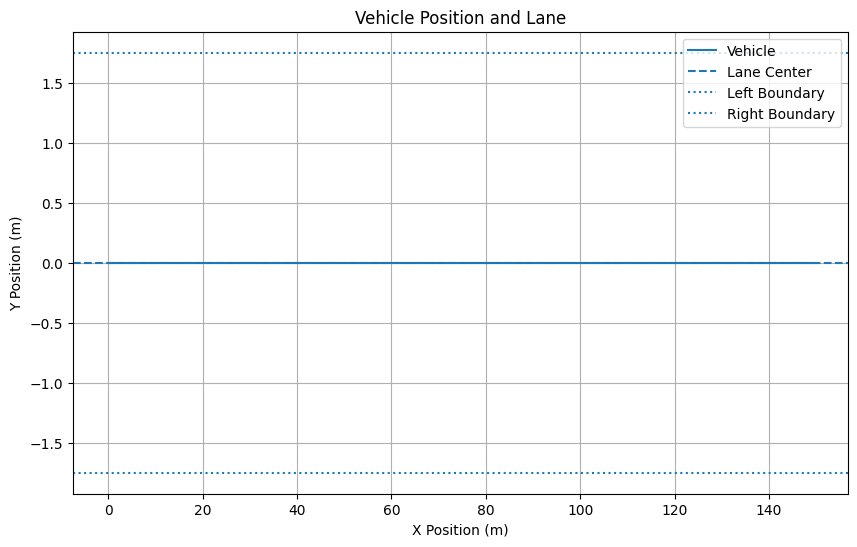

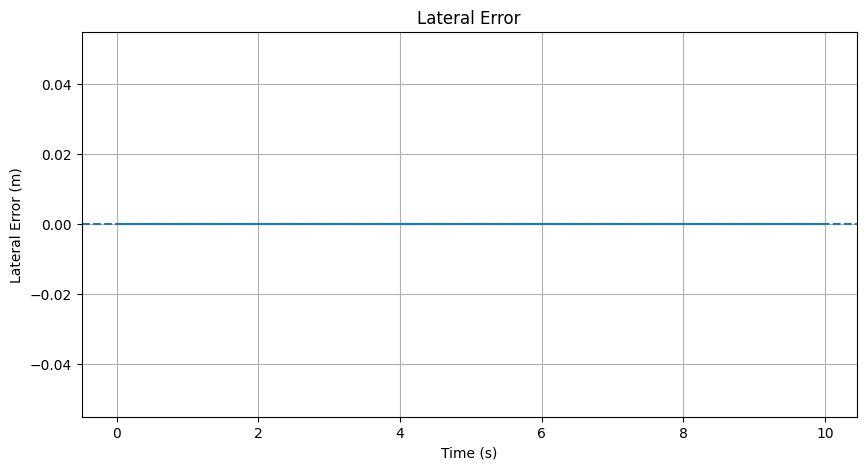

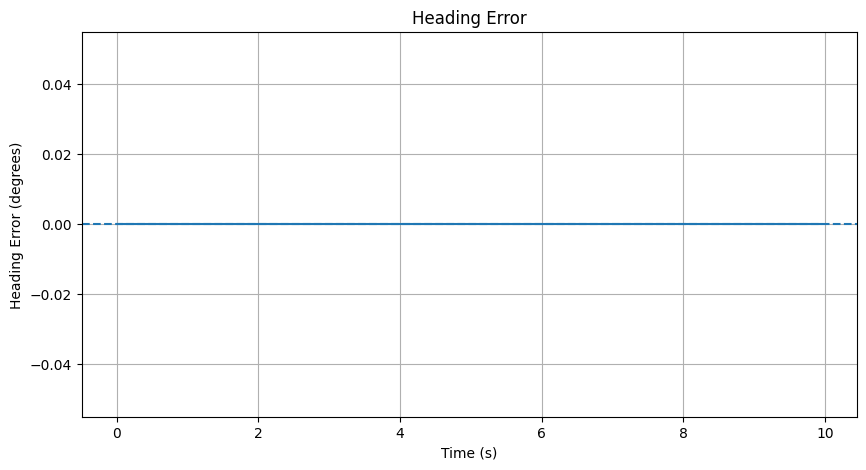

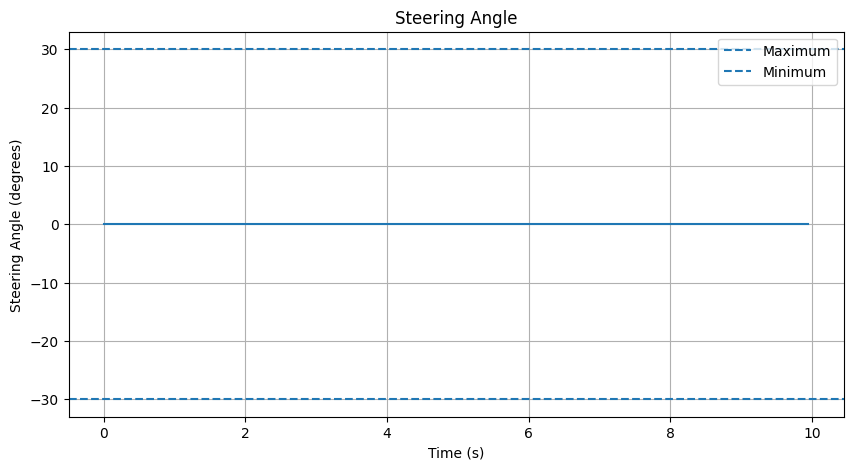

In [ ]:
h = simulator.history

plt.figure(figsize=(10, 6))
plt.plot(h["x"], h["y"], label="Vehicle")
plt.axhline(lane_state.center, linestyle="--", label="Lane Center")
plt.axhline(lane_state.center + lane_state.width / 2, linestyle=":", label="Left Boundary")
plt.axhline(lane_state.center - lane_state.width / 2, linestyle=":", label="Right Boundary")
plt.xlabel("X Position (m)"); plt.ylabel("Y Position (m)"); plt.title("Vehicle Position and Lane")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(h["time"], h["lateral_error"])
plt.axhline(0, linestyle="--")
plt.xlabel("Time (s)"); plt.ylabel("Lateral Error (m)"); plt.title("Lateral Error")
plt.grid(True); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(h["time"], np.rad2deg(h["heading_error"]))
plt.axhline(0, linestyle="--")
plt.xlabel("Time (s)"); plt.ylabel("Heading Error (degrees)"); plt.title("Heading Error")
plt.grid(True); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(h["time"], np.rad2deg(h["steering"]))
plt.axhline(np.rad2deg(control_params.max_steering_angle), linestyle="--", label="Maximum")
plt.axhline(-np.rad2deg(control_params.max_steering_angle), linestyle="--", label="Minimum")
plt.xlabel("Time (s)"); plt.ylabel("Steering Angle (degrees)"); plt.title("Steering Angle")
plt.legend(); plt.grid(True); plt.show()

## 18. Pruebas unitarias (casos de prueba, sección 26 del documento)

No dependen de ninguna imagen ni video: son casos inventados a mano para verificar
que la logica de decision se comporta como se espera (RNF-09).


In [ ]:
def run_case(name, condition, detail=""):
    status = "PASS" if condition else "FAIL"
    print(f"[{status}] {name} {detail}")

print("=== CASOS DE LANE KEEPING ===\n")

lane = LaneState(center=0.0, heading=0.0, width=3.5)
control = LaneKeepingController(ControlParams())

e_y = LaneGeometry.lateral_error(vehicle_y=0.0, lane=lane)
e_psi = LaneGeometry.heading_error(vehicle_yaw=0.0, lane=lane)
steering = control.compute_steering(e_y, e_psi)
run_case("Vehiculo centrado en carril", e_y == 0.0 and e_psi == 0.0 and steering == 0.0)

e_y = LaneGeometry.lateral_error(vehicle_y=1.5, lane=lane)
steering = control.compute_steering(e_y, heading_error=0.0)
run_case("Acercandose al limite izquierdo -> corrige a la derecha", steering < 0, f"(steering={steering:.3f})")

e_y = LaneGeometry.lateral_error(vehicle_y=-1.5, lane=lane)
steering = control.compute_steering(e_y, heading_error=0.0)
run_case("Acercandose al limite derecho -> corrige a la izquierda", steering > 0, f"(steering={steering:.3f})")

vehicle = VehicleParams()
safety = SafetyParams()
run_case("Vehiculo muy desviado -> detecta riesgo de salida",
         LaneGeometry.is_departing(2.0, lane, vehicle, safety) == True)
run_case("Vehiculo centrado -> NO detecta riesgo de salida",
         LaneGeometry.is_departing(0.0, lane, vehicle, safety) == False)

print("\n=== CASOS DE LANE-CHANGE VALIDATION ===\n")

validator = LaneChangeValidator(SafetyParams())
ego = VehicleState(x=0.0, y=0.0, yaw=0.0, speed=15.0)

run_case("Carril objetivo vacio -> permite cambio",
         validator.can_change_lane("LEFT", ego, 0, []) == True)

far_ahead = [TrackedObject(1, x=60.0, y=0.0, speed=14.0, lane=1)]
run_case("Vehiculo lejano delante -> permite cambio",
         validator.can_change_lane("LEFT", ego, 0, far_ahead) == True)

near_ahead = [TrackedObject(1, x=5.0, y=0.0, speed=14.0, lane=1)]
run_case("Vehiculo cercano delante -> rechaza cambio",
         validator.can_change_lane("LEFT", ego, 0, near_ahead) == False)

two_objects = [
    TrackedObject(1, x=60.0, y=0.0, speed=14.0, lane=1),
    TrackedObject(2, x=5.0, y=0.0, speed=14.0, lane=1),
]
run_case("Dos vehiculos, uno inseguro -> rechaza cambio",
         validator.can_change_lane("LEFT", ego, 0, two_objects) == False)

invalid_data = [TrackedObject(1, x=60.0, y=0.0, speed=14.0, lane=1, data_is_valid=False)]
run_case("Dato invalido en carril objetivo -> rechaza (conservador)",
         validator.can_change_lane("LEFT", ego, 0, invalid_data) == False)

print("\nSi todos salen [PASS], la logica de decision funciona como describe la seccion 26 del documento.")

=== CASOS DE LANE KEEPING ===

[PASS] Vehiculo centrado en carril 
[PASS] Acercandose al limite izquierdo -> corrige a la derecha (steering=-0.524)
[PASS] Acercandose al limite derecho -> corrige a la izquierda (steering=0.524)
[PASS] Vehiculo muy desviado -> detecta riesgo de salida 
[PASS] Vehiculo centrado -> NO detecta riesgo de salida 

=== CASOS DE LANE-CHANGE VALIDATION ===

[PASS] Carril objetivo vacio -> permite cambio 
[PASS] Vehiculo lejano delante -> permite cambio 
[PASS] Vehiculo cercano delante -> rechaza cambio 
[PASS] Dos vehiculos, uno inseguro -> rechaza cambio 
[PASS] Dato invalido en carril objetivo -> rechaza (conservador) 

Si todos salen [PASS], la logica de decision funciona como describe la seccion 26 del documento.
